In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [42]:
import os
print(os.getcwd())

C:\Users\yuliya.br


In [43]:
from pathlib import Path

DATA_PATH = Path('data/E Commerce Dataset.xlsx')

if not DATA_PATH.exists():
    DATA_PATH = Path(
        r'C:\Users\yuliya.br\Churn-Prediction\data\E Commerce Dataset.xlsx'
    )

print( DATA_PATH.exists())

True


In [44]:
df = pd.read_excel(DATA_PATH, sheet_name='E Comm')
df.head()

,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


In [45]:
df.shape

(5630, 20)

Для исследования используется датасет Ecommerce Customer Churn Analysis and Prediction с платформы Kaggle. https://www.kaggle.com/datasets/ankitverma2010/ecommerce-customer-churn-analysis-and-prediction?resource=download

Датасет содержит 5 630 наблюдений и 20 столбцов. Целевая переменная Churn показывает, ушёл клиент или остался.

In [46]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CustomerID                   5630 non-null   int64  
 1   Churn                        5630 non-null   int64  
 2   Tenure                       5366 non-null   float64
 3   PreferredLoginDevice         5630 non-null   object 
 4   CityTier                     5630 non-null   int64  
 5   WarehouseToHome              5379 non-null   float64
 6   PreferredPaymentMode         5630 non-null   object 
 7   Gender                       5630 non-null   object 
 8   HourSpendOnApp               5375 non-null   float64
 9   NumberOfDeviceRegistered     5630 non-null   int64  
 10  PreferedOrderCat             5630 non-null   object 
 11  SatisfactionScore            5630 non-null   int64  
 12  MaritalStatus                5630 non-null   object 
 13  NumberOfAddress   

In [47]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,5630.0,NaN,NaN,NaN,52815.5,1625.385339,50001.0,51408.25,52815.5,54222.75,55630.0
Churn,5630.0,NaN,NaN,NaN,0.168384,0.37424,0.0,0.0,0.0,0.0,1.0
Tenure,5366.0,NaN,NaN,NaN,10.189899,8.557241,0.0,2.0,9.0,16.0,61.0
PreferredLoginDevice,5630,3,Mobile Phone,2765,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CityTier,5630.0,NaN,NaN,NaN,1.654707,0.915389,1.0,1.0,1.0,3.0,3.0
WarehouseToHome,5379.0,NaN,NaN,NaN,15.639896,8.531475,5.0,9.0,14.0,20.0,127.0
PreferredPaymentMode,5630,7,Debit Card,2314,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,5630,2,Male,3384,NaN,NaN,NaN,NaN,NaN,NaN,NaN
HourSpendOnApp,5375.0,NaN,NaN,NaN,2.931535,0.721926,0.0,2.0,3.0,3.0,5.0
NumberOfDeviceRegistered,5630.0,NaN,NaN,NaN,3.688988,1.023999,1.0,3.0,4.0,4.0,6.0


Проведем анализ структуры данных. С помощью метода df.info() были изучены типы данных и количество заполненных значений.

Датасет содержит 5630 наблюдений и 20столбцов. Из них 7столбцов имеют тип int64, 8-float64 и 5-object. Целевая переменная Churn не содержит пропущенных значений.
В 7 признаках обнаружены пропуски. Наибольшее количество пропусков наблюдается в DaySinceLastOrder-307 значений (5,45%).

Также некоторые числовые признаки, например CityTier и Complain являются категориальными.

In [48]:

missing = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing %': df.isnull().mean() * 100
})

missing.sort_values(
    by='Missing %',
    ascending=False
)


,Missing Count,Missing %
DaySinceLastOrder,307,5.452931
OrderAmountHikeFromlastYear,265,4.706927
Tenure,264,4.689165
OrderCount,258,4.582593
CouponUsed,256,4.547069
HourSpendOnApp,255,4.529307
WarehouseToHome,251,4.458259
CustomerID,0,0.000000
PreferredLoginDevice,0,0.000000
Churn,0,0.000000


Посмотрим пропущенные значения
В датасете обнаружены пропуски в 7 из 20 столбцов.
Наибольшее количество пропусков в DaySinceLastOrder-307(5,45%).В остальных столбцах доля пропусков составляет около 4–5%.

Если смотреть по целевой переменной-Churn,то пропусков нет.


In [49]:

df.isnull().any(axis=1).sum()

np.int64(1856)

**Вывод по пропущенным значениям.**

В датасете 1856 строк (32,97%) содержат хотя бы одно пропущенное значение.

Хотя, в каждом отдельном признаке доля пропусков небольшая (около 4–5%), суммарно они затрагивают почти треть клиентов. При этом от общего числа ячеек пропущено всего 1,65%, то есть в целом датасет разрежен слабо.

Если удалить все строки с пропусками, мы потеряем значительную часть данных. Поэтому я планирую сохранить эти строки и заполнить пропуски после дополнительного анализа.

In [50]:
df.groupby(df['OrderCount'].isnull())['Tenure'].mean()

OrderCount
False     9.833007
True     17.255814
Name: Tenure, dtype: float64

In [51]:

df.groupby(df['OrderCount'].isnull())['Churn'].mean()


OrderCount
False    0.173120
True     0.069767
Name: Churn, dtype: float64

Я также проверила, связаны ли пропуски в OrderCount с целевой переменной Churn.

Оказалось, что среди клиентов с заполненным OrderCount доля оттока составляет 17,31%, а среди клиентов с пропущенным значением только 6,98%.
Ранее было обнаружено, что клиенты с пропусками в OrderCount в среднем дольше пользуются сервисом.

Таким образом, пропуски могут быть связаны с характеристиками клиентов. Поэтому я решила не удалять такие строки. При дальнейшем построении модели можно дополнительно учитывать сам факт наличия пропуска.

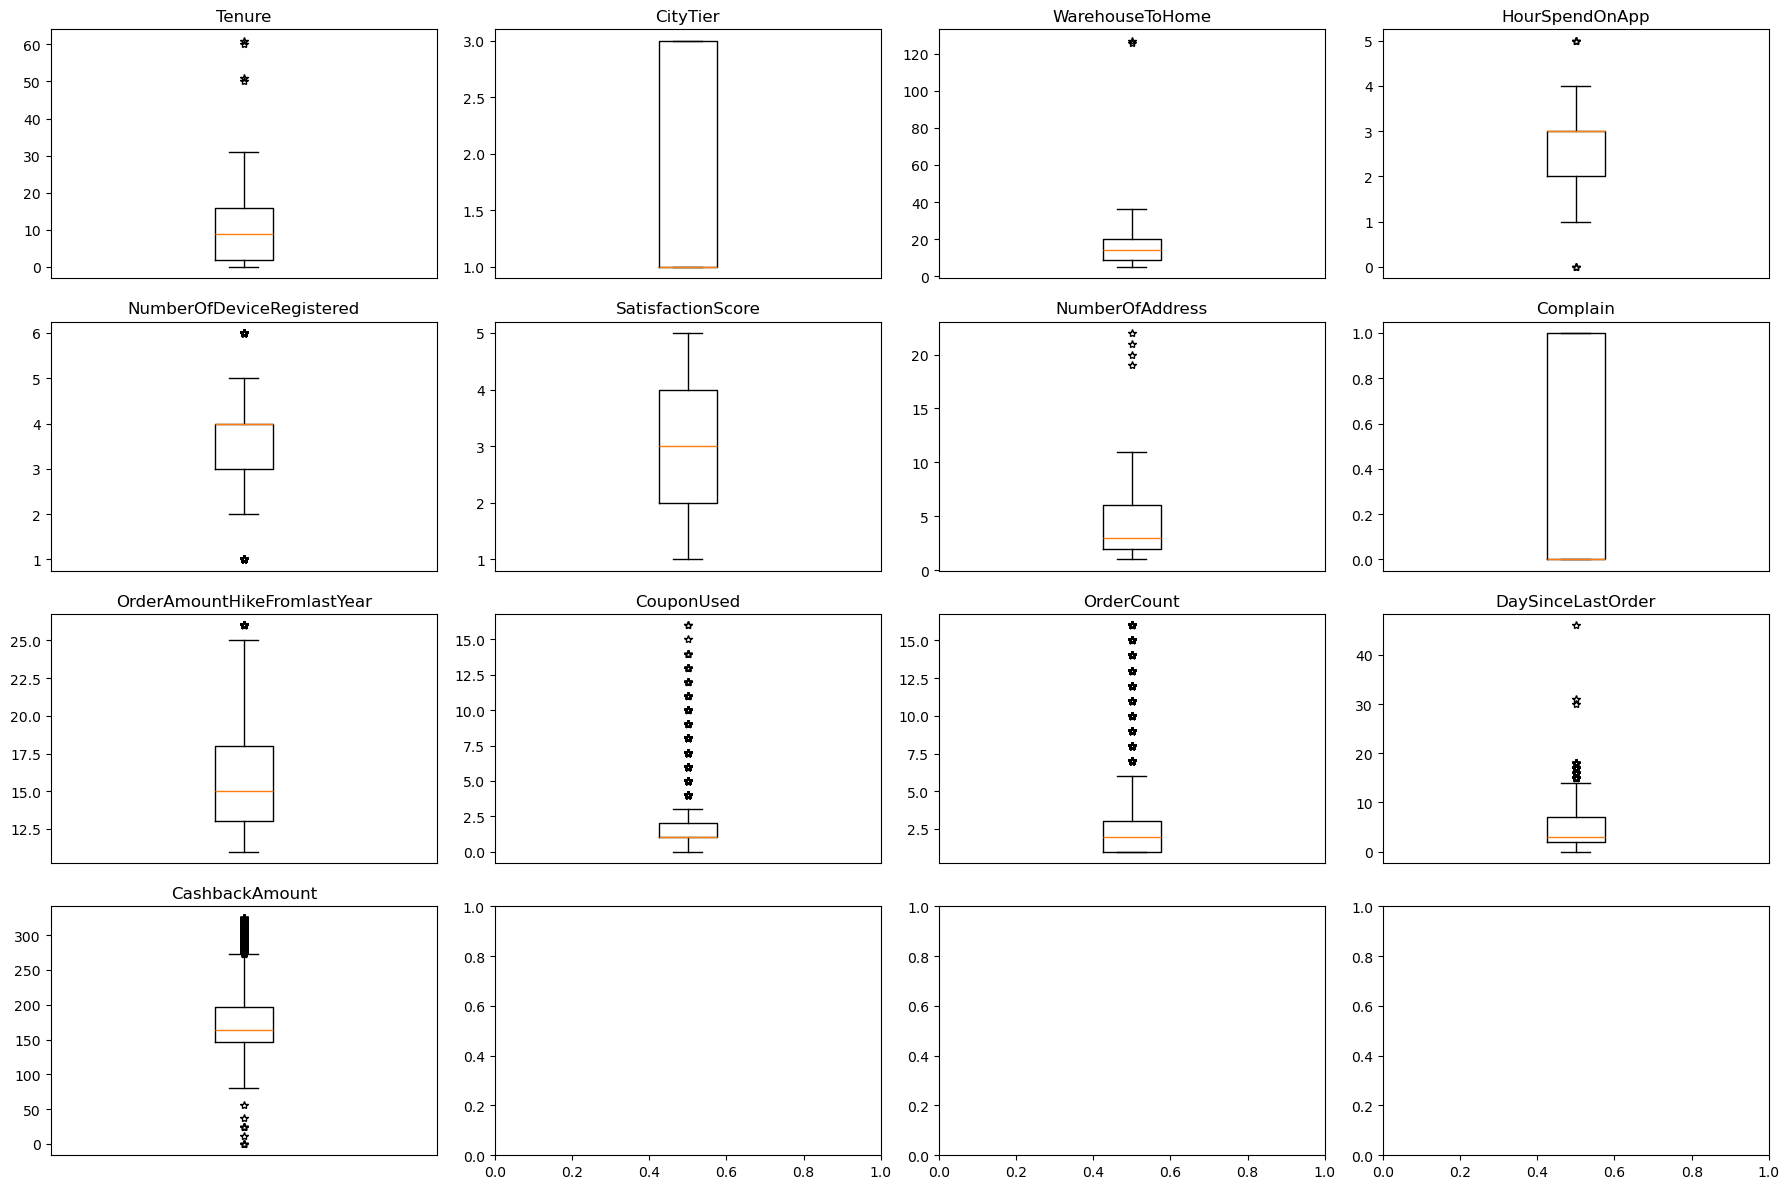

In [52]:

X = df.select_dtypes(include='number').drop(
    columns=['CustomerID', 'Churn']
)

fig, axes = plt.subplots(4, 4, figsize=(18, 12))

for ax, col in zip(axes.flat, X.columns):
    ax.boxplot(X[col].dropna(), sym='*')
    ax.set_title(col)
    ax.set_xticks([])

plt.tight_layout()
plt.show()


Анализ выбросов

Для поиска выбросов я построила диаграммы размаха (boxplot) для числовых признаков.

На графиках видно, что в некоторых столбцах присутствуют значения, которые сильно отличаются от большинства наблюдений.

Например, в WarehouseToHome максимальное значение составляет 127. Также выделяются большие значения в NumberOfAddress, CouponUsed, OrderCount и DaySinceLastOrder.

Например, большое количество заказов может характеризовать активного клиента, поэтому необходимо проверить выбросы, нет необходимости в удалении.

In [53]:

df[df['WarehouseToHome'] > 40]

,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
1309,51310,0,25.0,Computer,3,126.0,Debit Card,Male,2.0,3,Mobile,1,Married,3,0,15.0,1.0,1.0,0.0,134.82
4124,54125,0,26.0,Computer,3,127.0,Debit Card,Male,3.0,4,Mobile Phone,1,Married,4,0,16.0,2.0,2.0,1.0,159.82


In [54]:
plausible = {
    'Churn': (0, 1),
    'Tenure': (0, 100),
    'CityTier': (1, 3),
    'WarehouseToHome': (0, 200),
    'HourSpendOnApp': (0, 24),
    'NumberOfDeviceRegistered': (1, 20),
    'SatisfactionScore': (1, 5),
    'NumberOfAddress': (1, 50),
    'Complain': (0, 1),
    'OrderAmountHikeFromlastYear': (0, 100),
    'CouponUsed': (0, 100),
    'OrderCount': (0, 100),
    'DaySinceLastOrder': (0, 365),
    'CashbackAmount': (0, 1000)
}

errors = []

for col, (low, high) in plausible.items():
    bad = df.loc[(df[col] < low) | (df[col] > high), col]

    for row, value in bad.items():
        errors.append({
            'строка': row,
            'признак': col,
            'значение': value,
            'допустимый диапазон': f'{low} - {high}'
        })

pd.DataFrame(errors)


""


Проверка ошибочных значений

Для проверки данных я задала допустимые диапазоны значений для числовых признаков, используя подход из лекции.

Значений, выходящих за установленные диапазоны, обнаружено не было.

Дополнительно я проверила признак WarehouseToHome, так как на диаграмме размаха были заметны большие выбросы.

Были обнаружены два клиента со значениями 126 и 127, тогда как медиана составляет 14.

Эти значения могут быть ошибочными, но также могут отражать реальные большие расстояния. Поэтому на данном этапе я решила их не удалять.

Таким образом, явных ошибок по выбранным диапазонам не обнаружено, однако в данных есть выбросы.

In [55]:

for col in df.select_dtypes(include='object').columns:
    print(col)
    print(df[col].unique())
    print()


PreferredLoginDevice
['Mobile Phone' 'Phone' 'Computer']

PreferredPaymentMode
['Debit Card' 'UPI' 'CC' 'Cash on Delivery' 'E wallet' 'COD' 'Credit Card']

Gender
['Female' 'Male']

PreferedOrderCat
['Laptop & Accessory' 'Mobile' 'Mobile Phone' 'Others' 'Fashion' 'Grocery']

MaritalStatus
['Single' 'Divorced' 'Married']



In [56]:
# Проверяем полные дубликаты
print('Полные дубликаты:', df.duplicated().sum())

# Проверяем совпадения без CustomerID
duplicates = df.drop(columns='CustomerID').duplicated()

print('Без CustomerID:', duplicates.sum())
print('Доля совпадений:', round(duplicates.mean() * 100, 2), '%')

Полные дубликаты: 0
Без CustomerID: 556
Доля совпадений: 9.88 %


Проверка дубликатов

Я проверила данные на наличие повторяющихся строк. Полных дубликатов не обнаружено. Но если не учитывать CustomerID, то нашлось 556 повторяющихся строк (9,88%). Это могут быть разные клиенты с одинаковыми характеристиками, поэтому пока я решила оставить эти строки.

In [57]:
df_clean = df.copy()


In [58]:
df_clean['PreferredLoginDevice'] = df_clean['PreferredLoginDevice'].replace({
    'Phone': 'Mobile Phone'
})

df_clean['PreferredPaymentMode'] = df_clean['PreferredPaymentMode'].replace({
    'CC': 'Credit Card',
    'COD': 'Cash on Delivery'
})

In [59]:
df_clean[['PreferredLoginDevice', 'PreferredPaymentMode']].nunique()

PreferredLoginDevice    2
PreferredPaymentMode    5
dtype: int64

In [60]:

df_clean.isna().sum()

CustomerID                       0
Churn                            0
Tenure                         264
PreferredLoginDevice             0
CityTier                         0
WarehouseToHome                251
PreferredPaymentMode             0
Gender                           0
HourSpendOnApp                 255
NumberOfDeviceRegistered         0
PreferedOrderCat                 0
SatisfactionScore                0
MaritalStatus                    0
NumberOfAddress                  0
Complain                         0
OrderAmountHikeFromlastYear    265
CouponUsed                     256
OrderCount                     258
DaySinceLastOrder              307
CashbackAmount                   0
dtype: int64

In [61]:
# Общая доля пропущенных значений
print('Доля пропусков:', round(df.isna().sum().sum() / df.size * 100, 2), '%')

# Сколько пропусков встречается в одной строке
df.isna().sum(axis=1).value_counts().sort_index()

Доля пропусков: 1.65 %


0    3774
1    1856
Name: count, dtype: int64

Дополнительная проверка пропусков

Я также проверила общую долю пропущенных значений в датасете. Она составляет 1,65%.

Из 5 630 строк в 3 774 пропусков нет, а в 1 856 строках есть только один пропуск.

Получается, что пропущенных значений немного, но они встречаются почти у трети клиентов (32,97%).

Поэтому я решила не удалять эти строки, а заполнить пропуски медианой.

In [62]:
# Проверяем отток среди клиентов с пропусками
for col in df.columns[df.isna().any()]:
    missing = df[col].isna()

    churn_missing = df.loc[missing, 'Churn'].mean() * 100
    churn_filled = df.loc[~missing, 'Churn'].mean() * 100

    print(col)
    print('Отток с пропуском:', round(churn_missing, 2), '%')
    print('Отток без пропуска:', round(churn_filled, 2), '%')
    
    print()

Tenure
Отток с пропуском: 30.68 %
Отток без пропуска: 16.16 %

WarehouseToHome
Отток с пропуском: 33.47 %
Отток без пропуска: 16.06 %

HourSpendOnApp
Отток с пропуском: 22.75 %
Отток без пропуска: 16.56 %

OrderAmountHikeFromlastYear
Отток с пропуском: 5.28 %
Отток без пропуска: 17.41 %

CouponUsed
Отток с пропуском: 3.12 %
Отток без пропуска: 17.49 %

OrderCount
Отток с пропуском: 6.98 %
Отток без пропуска: 17.31 %

DaySinceLastOrder
Отток с пропуском: 17.59 %
Отток без пропуска: 16.8 %



Связь пропусков с оттоком клиентов

Я проверила, отличается ли отток у клиентов с пропущенными значениями.

Оказалось, что в некоторых признаках разница довольно большая. Например, если отсутствует Tenure, доля оттока составляет 30,68%, а если значение заполнено — 16,16%. Похожая ситуация с WarehouseToHome.

А вот для CouponUsed, OrderCount и OrderAmountHikeFromlastYear ситуация обратная: среди клиентов с пропусками отток значительно ниже.

Получается, что пропуски могут быть связаны с оттоком клиентов. Поэтому при построении модели стоит проверить, поможет ли добавление отдельных признаков, показывающих, где были пропуски.


In [63]:
# Проверяем полные дубликаты
print('Полные дубликаты:', df.duplicated().sum())

# Проверяем совпадения без CustomerID
duplicates = df.drop(columns='CustomerID').duplicated()

print('Совпадения без CustomerID:', duplicates.sum())
print('Доля совпадений:', round(duplicates.mean() * 100, 2), '%')


Полные дубликаты: 0
Совпадения без CustomerID: 556
Доля совпадений: 9.88 %


Проверка дубликатов

Я проверила данные на наличие повторяющихся строк.

Полных дубликатов не обнаружено. Но если не учитывать CustomerID, то нашлось 556 повторяющихся строк (9,88%).

Это могут быть разные клиенты с одинаковыми характеристиками, поэтому пока я решила оставить эти строки.

In [64]:
df_clean = df.copy()

cols = [
    'Tenure', 'WarehouseToHome', 'HourSpendOnApp',
    'OrderAmountHikeFromlastYear', 'CouponUsed',
    'OrderCount', 'DaySinceLastOrder'
]

for col in cols:
    df_clean[col + '_missing'] = df_clean[col].isna().astype(int)
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

df_clean.isna().sum()

CustomerID                             0
Churn                                  0
Tenure                                 0
PreferredLoginDevice                   0
CityTier                               0
WarehouseToHome                        0
PreferredPaymentMode                   0
Gender                                 0
HourSpendOnApp                         0
NumberOfDeviceRegistered               0
PreferedOrderCat                       0
SatisfactionScore                      0
MaritalStatus                          0
NumberOfAddress                        0
Complain                               0
OrderAmountHikeFromlastYear            0
CouponUsed                             0
OrderCount                             0
DaySinceLastOrder                      0
CashbackAmount                         0
Tenure_missing                         0
WarehouseToHome_missing                0
HourSpendOnApp_missing                 0
OrderAmountHikeFromlastYear_missing    0
CouponUsed_missi

Обработка пропущенных значений

В исходном датасете пропуски были обнаружены в 7 числовых признаках. Их доля составляла примерно 4,5–5,5% для каждого признака.

Для заполнения пропусков я выбрала медиану, так как она меньше зависит от выбросов, чем среднее значение.

Перед заполнением я также добавила 7 новых столбцов, которые показывают, где изначально были пропуски: 1 пропуск был, 0 — пропуска не было.

После обработки в датасете стало 27 столбцов, пропущенных значений не осталось.

Анализ показал, что пропуски могут быть связаны с оттоком клиентов. Поэтому при построении модели я планирую проверить, помогут ли новые столбцы улучшить качество предсказаний.

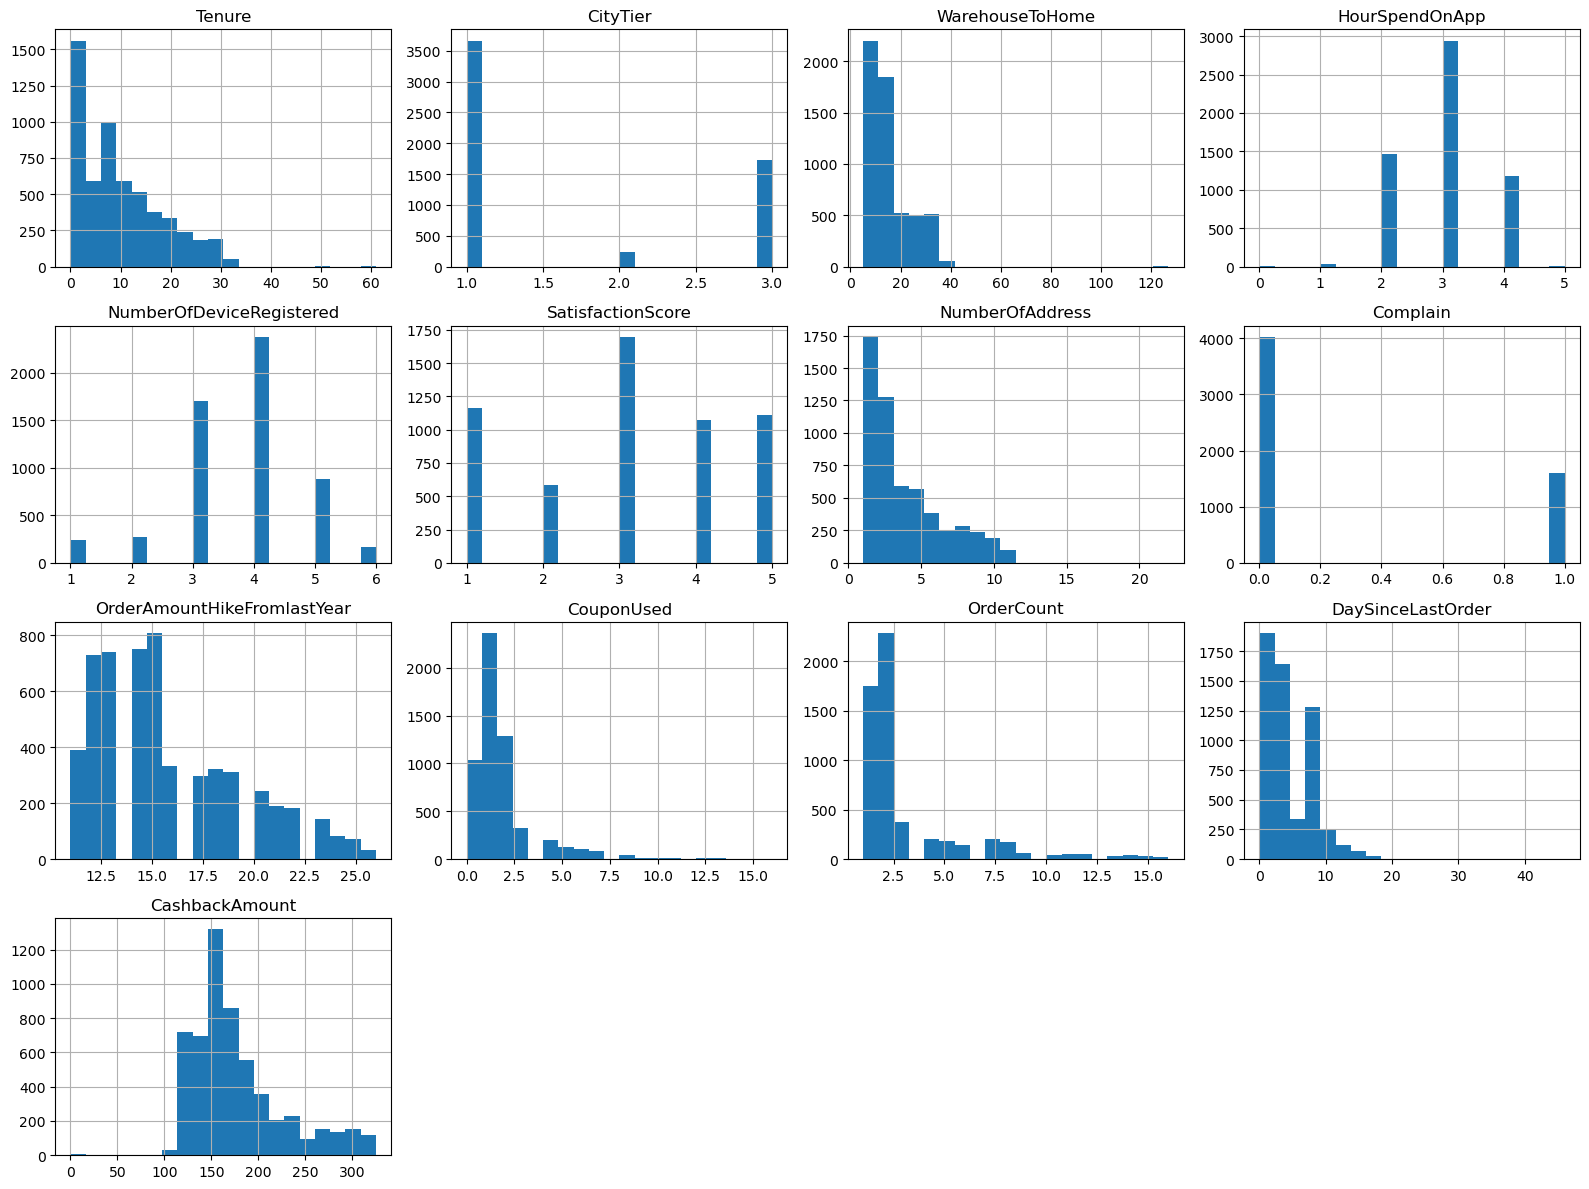

In [65]:
num_cols = df_clean.select_dtypes(include='number').columns

num_cols = [
    col for col in num_cols
    if col not in ['CustomerID', 'Churn'] and not col.endswith('_missing')
]

df_clean[num_cols].hist(figsize=(16, 12), bins=20)

plt.tight_layout()
plt.show()

Анализ распределений признаков

Я построила гистограммы, чтобы посмотреть, как распределяются числовые признаки.

По графикам видно, что большинство клиентов имеют небольшой стаж, используют немного купонов и совершают небольшое количество заказов.

В WarehouseToHome заметны два очень больших значения, которые мы уже обнаружили при проверке выбросов.

Также видно, что некоторые признаки, например CityTier, SatisfactionScore и Complain, принимают только определённые значения.

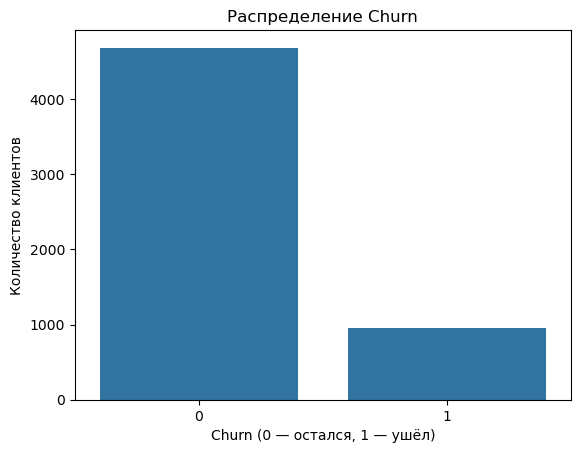

Churn
0    83.161634
1    16.838366
Name: proportion, dtype: float64


In [66]:
sns.countplot(data=df_clean, x='Churn')
plt.title('Распределение Churn')
plt.xlabel('Churn (0 — остался, 1 — ушёл)')
plt.ylabel('Количество клиентов')
plt.show()

print(df_clean['Churn'].value_counts(normalize=True) * 100)


Анализ целевой переменной Churn

Целевая переменная Churn принимает два значения:

0 — клиент остался (83,16%, 4 682 клиента).

1 — клиент ушёл (16,84%, 948 клиентов).

В датасете наблюдается дисбаланс классов: клиентов, которые остались, значительно больше, чем ушедших.

In [81]:

corr = df_clean[list(num_cols) + ['Churn']].corr()
corr['Churn'].sort_values()

Tenure                        -0.337831
DaySinceLastOrder             -0.155871
CashbackAmount                -0.154118
OrderCount                    -0.024038
OrderAmountHikeFromlastYear   -0.007075
CouponUsed                    -0.001430
HourSpendOnApp                 0.018816
NumberOfAddress                0.043931
WarehouseToHome                0.069544
CityTier                       0.084703
SatisfactionScore              0.105481
NumberOfDeviceRegistered       0.107939
Complain                       0.250188
Churn                          1.000000
Name: Churn, dtype: float64

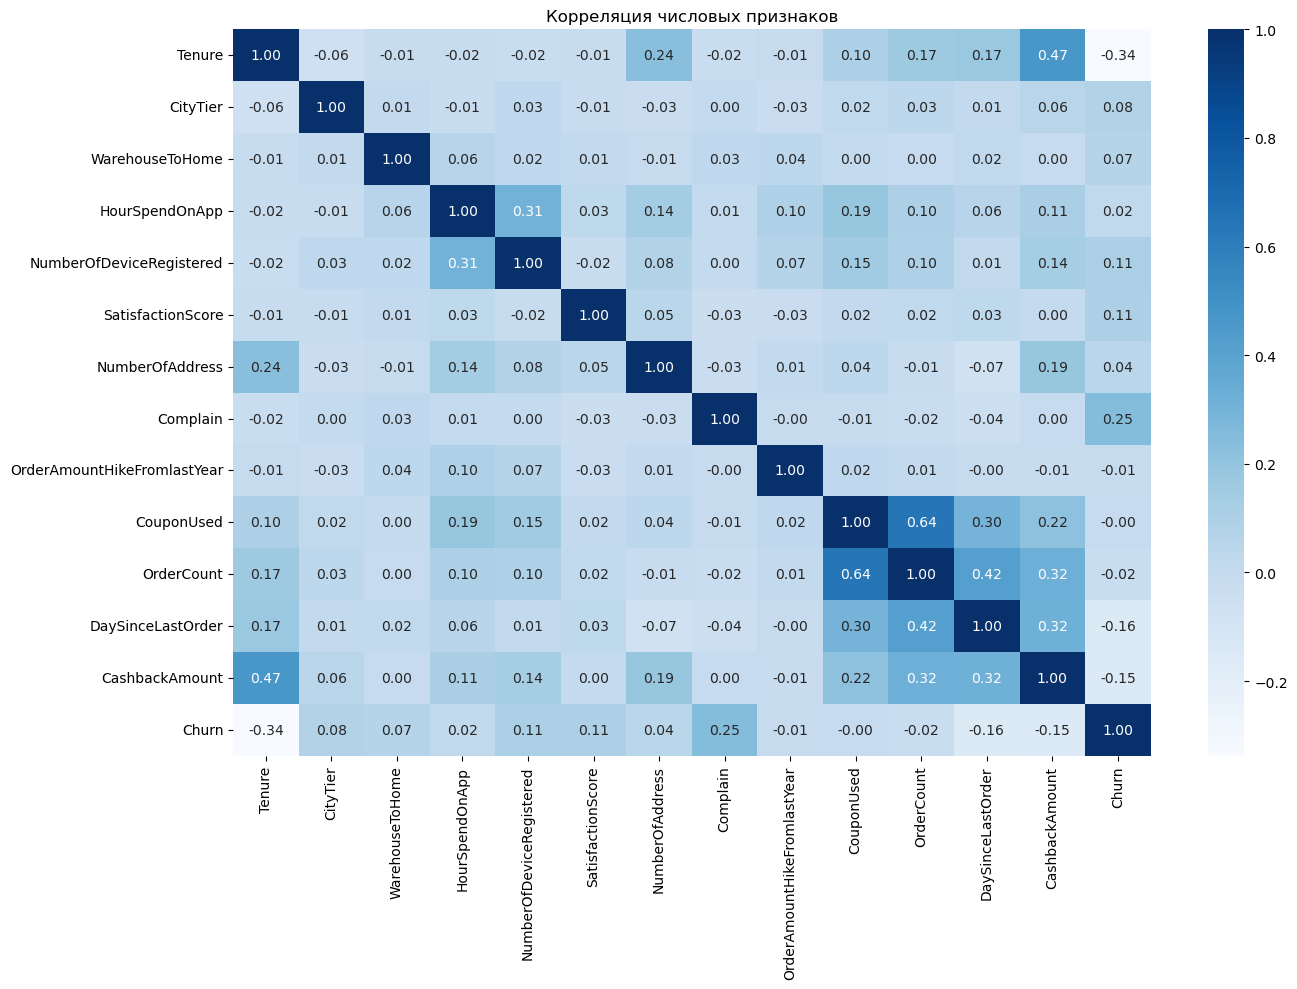

In [68]:

# Выбираем числовые признаки без новых столбцов
cols = list(num_cols) + ['Churn']

# Строим корреляционную матрицу
corr = df_clean[cols].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr, cmap='Blues', annot=True, fmt='.2f')

plt.title('Корреляция числовых признаков')
plt.tight_layout()
plt.show()


Корреляционный анализ

Для оценки связи числовых признаков с целевой переменной Churn была рассчитана матрица корреляций.

Наиболее заметные связи обнаружены у следующих признаков:

Tenure (−0,338) — отрицательная связь: клиенты с большим стажем реже уходят.

Complain (+0,250) — положительная связь: наличие жалоб связано с более высоким оттоком.

DaySinceLastOrder (−0,156) — слабая отрицательная связь.

CashbackAmount (−0,154) — слабая отрицательная связь.

У большинства остальных числовых признаков линейная связь с Churn слабая.
Также я заметила сильную положительную корреляцию между CouponUsed и OrderCount (0,75). Это означает, что клиенты с большим количеством заказов обычно используют больше купонов.

In [69]:
df_clean.groupby('Complain')['Churn'].mean() * 100


Complain
0    10.928962
1    31.670823
Name: Churn, dtype: float64

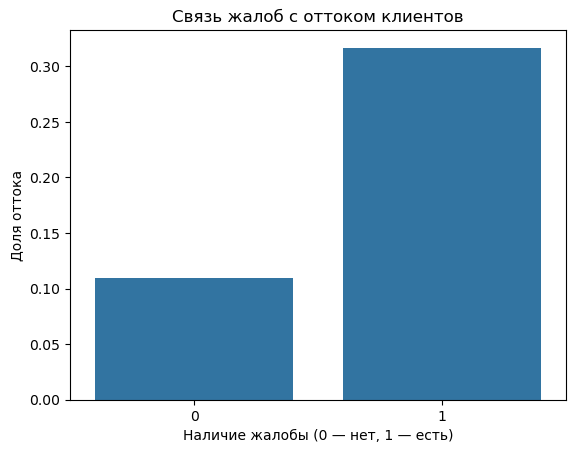

In [70]:
# Доля оттока среди клиентов с жалобами и без жалоб

sns.barplot(data=df_clean, x='Complain', y='Churn', errorbar=None)

plt.title('Связь жалоб с оттоком клиентов')
plt.xlabel('Наличие жалобы (0 — нет, 1 — есть)')
plt.ylabel('Доля оттока')
plt.show()


Связь жалоб с оттоком клиентов

Я построила график, чтобы сравнить отток среди клиентов с жалобами и без них.

На графике видно, что среди клиентов, которые оставляли жалобы, доля оттока составляет около 32%, а среди остальных-около 11%.

Получается, что клиенты с жалобами уходят чаще.

In [71]:
#Ранее мы обнаружили, что Tenure имеет самую сильную корреляцию с Churn (−0,338).
#Посмотрим, как отличается стаж клиентов, которые остались, от стажа тех, кто ушёл.

df_clean.groupby('Churn')['Tenure'].median()


Churn
0    10.0
1     1.0
Name: Tenure, dtype: float64

In [72]:
# Разделяем клиентов на группы по стажу
df_clean['TenureGroup'] = pd.cut(
    df_clean['Tenure'],
    bins=[-1, 1, 3, 6, 12, 24, 100],
    labels=['0–1', '2–3', '4–6', '7–12', '13–24', '25+']
)

# Сравниваем отток по стажу и наличию жалоб
table = pd.pivot_table(
    df_clean,
    values='Churn',
    index='TenureGroup',
    columns='Complain',
    aggfunc='mean',
    observed=True
)

(table * 100).round(1)


Complain,0,1
TenureGroup,,
0–1,39.4,72.9
2–3,4.2,26.3
4–6,3.1,21.9
7–12,6.4,20.0
13–24,4.1,12.6
25+,0.0,0.0


Связь стажа клиента и жалоб с оттоком

Я сделала сводную таблицу, чтобы посмотреть, как стаж клиента и наличие жалоб вместе связаны с оттоком.

Оказалось, что самый высокий отток среди клиентов со стажем 0–1 и жалобами-72,9%. Даже среди клиентов без жалоб в этой группе отток довольно высокий- 39,4%.

У клиентов с большим стажем доля оттока в основном ниже. При этом почти во всех группах клиенты с жалобами уходят чаще, чем без жалоб.

Таким образом, стаж клиента и наличие жалоб могут быть полезными признаками для прогнозирования оттока.

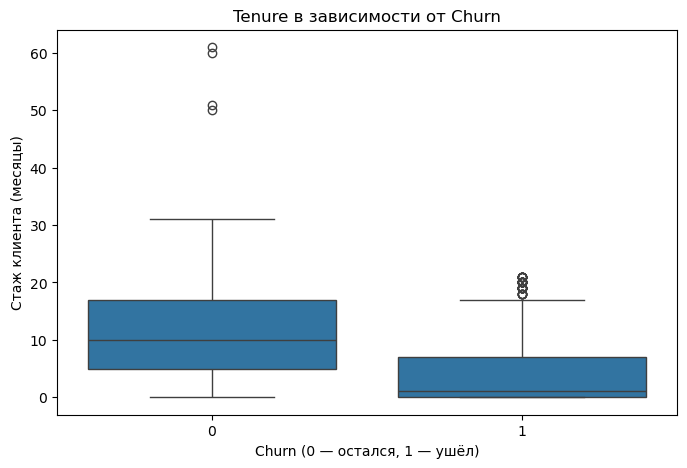

In [73]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df_clean, x='Churn', y='Tenure')

plt.title('Tenure в зависимости от Churn')
plt.xlabel('Churn (0 — остался, 1 — ушёл)')
plt.ylabel('Стаж клиента (месяцы)')

plt.show()



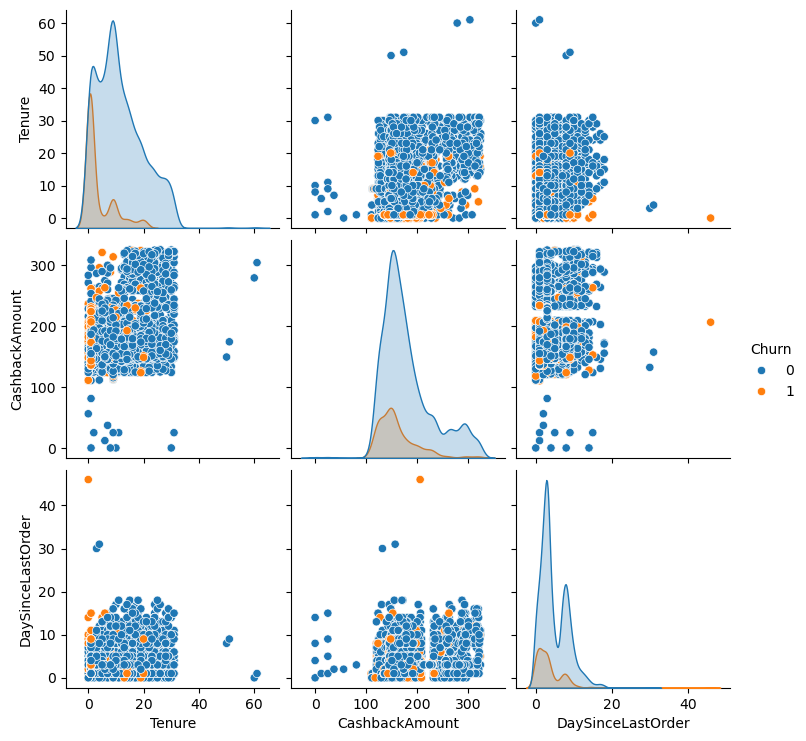

In [74]:
sns.pairplot(
    df_clean,
    vars=['Tenure', 'CashbackAmount', 'DaySinceLastOrder'],
    hue='Churn'
)

plt.show()


Анализ взаимосвязей признаков с помощью Pairplot

Для визуального анализа взаимосвязей были выбраны признаки Tenure, CashbackAmount и DaySinceLastOrder. Цвет точек соответствует целевой переменной Churn.

Наиболее заметные различия между группами наблюдаются по признаку Tenure. Ушедшие клиенты преимущественно имеют небольшой стаж использования сервиса.

Для CashbackAmount и DaySinceLastOrder распределения двух групп значительно пересекаются, поэтому по отдельности эти признаки не позволяют чётко разделить клиентов на ушедших и оставшихся.

На диаграммах также присутствуют отдельные выбросы.

In [75]:
df_clean.groupby('PreferredPaymentMode')['Churn'].mean() * 100

PreferredPaymentMode
CC                  21.611722
COD                 28.767123
Cash on Delivery    15.436242
Credit Card         12.858095
Debit Card          15.384615
E wallet            22.801303
UPI                 17.391304
Name: Churn, dtype: float64

Связь способа оплаты с оттоком клиентов

Для анализа категориального признака PreferredPaymentMode была рассчитана доля ушедших клиентов для каждого способа оплаты.

Наибольшая доля оттока наблюдается среди клиентов, предпочитающих оплату при получении заказа (Cash on Delivery)-24,90%, а также электронные кошельки (E wallet) -22,80%.

Наименьшая доля оттока наблюдается среди клиентов, предпочитающих кредитные карты (Credit Card)-14,21%.

Таким образом, предпочитаемый способ оплаты может быть связан с оттоком клиентов и представлять интерес для дальнейшего моделирования.

При этом для более надёжных выводов необходимо учитывать количество клиентов в каждой группе.

In [76]:

df_clean.groupby('PreferredPaymentMode')['Churn'].agg(['count', 'sum', 'mean'])

,count,sum,mean
PreferredPaymentMode,,,
CC,273,59,0.216117
COD,365,105,0.287671
Cash on Delivery,149,23,0.154362
Credit Card,1501,193,0.128581
Debit Card,2314,356,0.153846
E wallet,614,140,0.228013
UPI,414,72,0.173913


Анализ способа оплаты и оттока

Дополнительно было проверено количество клиентов в каждой категории PreferredPaymentMode.

Размер групп составляет от 414 до 2 314 клиентов.

Наибольшая доля оттока наблюдается при оплате Cash on Delivery (24,90%) и E wallet (22,80%). Наименьшая при использовании Credit Card (14,21%).

Таким образом, наблюдается различие в долях оттока между способами оплаты. 

In [77]:
for col in df_clean.select_dtypes(include='object').columns:
    if col != 'PreferredPaymentMode':
        print(col)
        print(df_clean.groupby(col)['Churn'].mean() * 100)
        print()


PreferredLoginDevice
PreferredLoginDevice
Computer        19.828641
Mobile Phone    12.585895
Phone           22.420796
Name: Churn, dtype: float64

Gender
Gender
Female    15.494212
Male      17.730496
Name: Churn, dtype: float64

PreferedOrderCat
PreferedOrderCat
Fashion               15.496368
Grocery                4.878049
Laptop & Accessory    10.243902
Mobile                27.194067
Mobile Phone          27.537372
Others                 7.575758
Name: Churn, dtype: float64

MaritalStatus
MaritalStatus
Divorced    14.622642
Married     11.520429
Single      26.726058
Name: Churn, dtype: float64



Анализ категориальных признаков и оттока

Для категориальных признаков была рассчитана доля ушедших клиентов в каждой группе.

Анализ показал следующие закономерности:

PreferredLoginDevice: клиенты, предпочитающие компьютер, имеют более высокую долю оттока (19,83%), чем пользователи мобильных устройств (15,62%).

Gender: доля оттока среди мужчин составляет 17,73%, среди женщин 15,49%. Различие относительно небольшое.

PreferedOrderCat: наиболее высокий отток наблюдается в категориях Mobile Phone (27,54%) и Mobile (27,19%), а наиболее низкий в Grocery (4,88%).

MaritalStatus: среди клиентов категории Single доля оттока составляет 26,73%, что заметно выше, чем среди Married (11,52%).

Таким образом, наиболее выраженные различия в долях оттока наблюдаются для предпочитаемой категории товаров и семейного положения.

In [78]:
df_clean.groupby('PreferedOrderCat')['Churn'].agg(['count', 'sum', 'mean'])

,count,sum,mean
PreferedOrderCat,,,
Fashion,826,128,0.154964
Grocery,410,20,0.048780
Laptop & Accessory,2050,210,0.102439
Mobile,809,220,0.271941
Mobile Phone,1271,350,0.275374
Others,264,20,0.075758


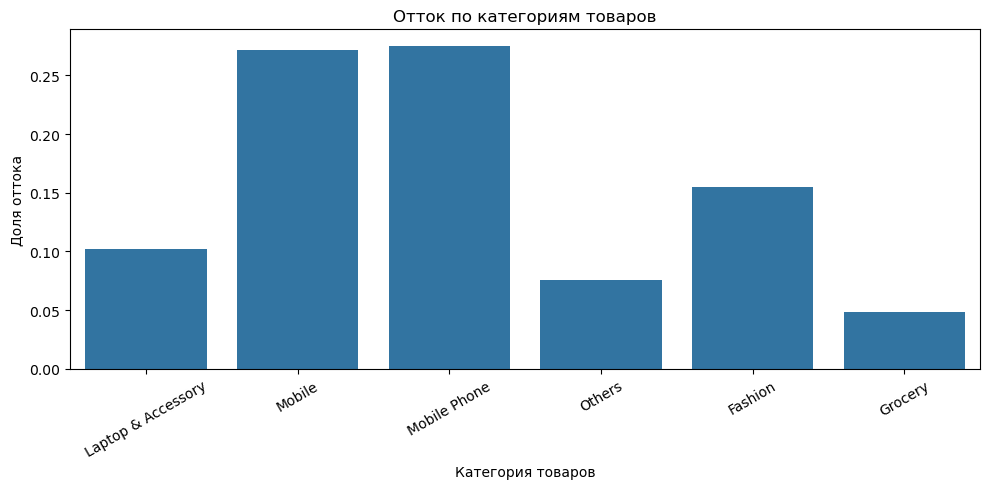

In [79]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df_clean,
    x='PreferedOrderCat',
    y='Churn',
    errorbar=None
)

plt.title('Отток по категориям товаров')
plt.xlabel('Категория товаров')
plt.ylabel('Доля оттока')
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

Отток по категориям товаров

Я построила график, чтобы сравнить долю оттока в разных категориях товаров.

Самый высокий отток наблюдается в категориях Mobile и Mobile Phone-около 27%. Самый низкий-в Grocery, около 5%.

Получается, что предпочитаемая категория товаров может быть связана с оттоком клиентов.

In [80]:
data_dict = pd.read_excel(DATA_PATH, sheet_name='Data Dict')
data_dict

,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3
0,NaN,Data,Variable,Discerption
1,NaN,E Comm,CustomerID,Unique customer ID
2,NaN,E Comm,Churn,Churn Flag
3,NaN,E Comm,Tenure,Tenure of customer in organization
4,NaN,E Comm,PreferredLoginDevice,Preferred login device of customer
5,NaN,E Comm,CityTier,City tier
6,NaN,E Comm,WarehouseToHome,Distance in between warehouse to home of customer
7,NaN,E Comm,PreferredPaymentMode,Preferred payment method of customer
8,NaN,E Comm,Gender,Gender of customer
9,NaN,E Comm,HourSpendOnApp,Number of hours spend on mobile application or...


Вывод

В ходе разведочного анализа данных (EDA) был исследован датасет, содержащий информацию о 5 630 клиентах интернет-магазина.

В процессе анализа были выявлены пропущенные значения в 7 признаках, которые были заполнены медианой. Дополнительно были созданы индикаторы пропусков, проверены дубликаты и  выбросы. Значения, не являющиеся однозначными ошибками, были сохранены для дальнейшего анализа.

Анализ целевой переменной показал, что доля ушедших клиентов составляет 16,84%, что свидетельствует, что есть дисбаланс классов.

Наиболее заметная связь с оттоком выявлена у признаков Tenure и Complain. Клиенты с меньшим стажем использования сервиса и наличием жалоб характеризуются более высокой долей оттока. Также обнаружены различия в уровне оттока в зависимости от категории товаров, способа оплаты и семейного положения.

Полученные результаты позволяют выделить потенциально значимые признаки для прогнозирования оттока клиентов.